# Credit Card Classification — Reproduction of the MSc Thesis in Kaggle

This notebook ports the thesis workflow and the hyperparameters reported in the PDF to Kaggle: Decision Tree, Random Forest, XGBoost, 70/30 train-test split, GridSearchCV with ROC-AUC scoring, evaluation with accuracy / precision / recall / F1 / ROC-AUC, confusion matrices, feature importance, and SHAP for XGBoost.

**Important methodological note:** the public Kaggle files `application_record.csv` and `credit_record.csv` do not contain an explicit bank approval/rejection label. The notebook therefore constructs a *proxy target* from payment-history status, as documented below. Results are not directly comparable with the thesis unless the target construction and preprocessing are identical.

The thesis describes SMOTE and also reports results without SMOTE. In this notebook, SMOTE is applied **only to training folds** to avoid contaminating the test set. This is a deliberate methodological safeguard and may produce different metrics from the original experiment if the original resampled before splitting.

### Kaggle setup
1. In your Kaggle Notebook, select **Add Input** and add **Credit Card Approval Prediction** by `rikdifos`.
2. Run the cells in order.


In [1]:
# Ensure compatible scikit-learn / imbalanced-learn / xgboost versions when running on Kaggle
import os, sys
if os.path.exists("/kaggle/input"):
    get_ipython().run_line_magic("pip", "install -q --no-cache-dir --upgrade xgboost==2.1.4 scikit-learn==1.6.1 imbalanced-learn==0.13.0")

In [2]:
# Core libraries (normally available in Kaggle)
import os
import glob
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

print("Libraries loaded.")

Libraries loaded.


In [3]:
# Locate the CSV files under /kaggle/input (Kaggle) or ./data (Local/GitHub)
search_roots = ["/kaggle/input", "./data", "../data", "."]
application_paths = []
credit_paths = []

for root in search_roots:
    if os.path.exists(root):
        application_paths.extend(glob.glob(os.path.join(root, "**", "application_record.csv"), recursive=True))
        credit_paths.extend(glob.glob(os.path.join(root, "**", "credit_record.csv"), recursive=True))

if not application_paths or not credit_paths:
    raise FileNotFoundError(
        "Could not find application_record.csv and credit_record.csv. "
        "In Kaggle, click 'Add Input' and add the 'Credit Card Approval Prediction' dataset, "
        "or place the files in the ./data directory locally."
    )

application_path = application_paths[0]
credit_path = credit_paths[0]

print("Application file:", application_path)
print("Credit file:", credit_path)

application = pd.read_csv(application_path)
credit = pd.read_csv(credit_path)

print("Application shape:", application.shape)
print("Credit shape:", credit.shape)

display(application.head())
display(credit.head())

Application file: ./data\application_record.csv
Credit file: ./data\credit_record.csv


Application shape: (438557, 18)
Credit shape: (1048575, 3)


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


## 1. Initial data checks and exploratory analysis

Application columns and data types:
<class 'pandas.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  str    
 2   FLAG_OWN_CAR         438557 non-null  str    
 3   FLAG_OWN_REALTY      438557 non-null  str    
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  str    
 7   NAME_EDUCATION_TYPE  438557 non-null  str    
 8   NAME_FAMILY_STATUS   438557 non-null  str    
 9   NAME_HOUSING_TYPE    438557 non-null  str    
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64

None


Missing values in application data:


OCCUPATION_TYPE        134203
ID                          0
CODE_GENDER                 0
FLAG_OWN_CAR                0
CNT_CHILDREN                0
FLAG_OWN_REALTY             0
NAME_INCOME_TYPE            0
NAME_EDUCATION_TYPE         0
NAME_FAMILY_STATUS          0
AMT_INCOME_TOTAL            0
NAME_HOUSING_TYPE           0
DAYS_BIRTH                  0
FLAG_MOBIL                  0
DAYS_EMPLOYED               0
FLAG_WORK_PHONE             0
FLAG_PHONE                  0
FLAG_EMAIL                  0
CNT_FAM_MEMBERS             0
dtype: int64


Duplicate application rows: 0
Duplicate application IDs: 47

Payment status distribution:


STATUS
C    442031
0    383120
X    209230
1     11090
5      1693
2       868
3       320
4       223
Name: count, dtype: int64

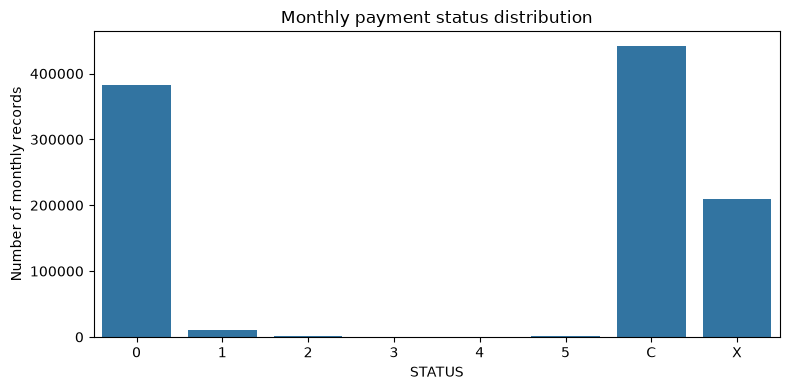

In [4]:
print("Application columns and data types:")
display(application.info())

print("\nMissing values in application data:")
display(application.isna().sum().sort_values(ascending=False).head(20))

print("\nDuplicate application rows:", application.duplicated().sum())
print("Duplicate application IDs:", application["ID"].duplicated().sum())

print("\nPayment status distribution:")
display(credit["STATUS"].astype(str).value_counts(dropna=False))

plt.figure(figsize=(8, 4))
sns.countplot(data=credit, x=credit["STATUS"].astype(str),
              order=sorted(credit["STATUS"].astype(str).unique()))
plt.title("Monthly payment status distribution")
plt.xlabel("STATUS")
plt.ylabel("Number of monthly records")
plt.tight_layout()
plt.show()

## 2. Preprocessing and target construction

The source data has multiple monthly records per customer in `credit_record.csv`. To avoid the same customer's records appearing in both train and test sets, the payment history is aggregated to one label per `ID` before joining it to the application data.

The label follows the mapping described in the thesis. It should be interpreted as a proxy for payment-history quality, not as a true application-approval label.

In [5]:
# Keep one application row per customer ID, as in the thesis workflow.
application = application.drop_duplicates(subset="ID", keep="first").copy()

# Standardize status values as strings and retain known status categories.
credit["STATUS"] = credit["STATUS"].astype(str).str.strip()
valid_statuses = {"0", "1", "2", "3", "4", "5", "C", "X"}
credit = credit[credit["STATUS"].isin(valid_statuses)].copy()

# Thesis mapping:
# C, X, 0 -> label 1
# 1, 2, 3, 4, 5 -> label 0
# Because records are monthly, customer-level target is 0 if any severe delinquency
# status (1-5) occurs; otherwise it is 1.
credit["severe_delinquency"] = credit["STATUS"].isin(["1", "2", "3", "4", "5"]).astype(int)

customer_target = (
    credit.groupby("ID", as_index=False)["severe_delinquency"]
    .max()
    .rename(columns={"severe_delinquency": "any_severe_delinquency"})
)
customer_target["TARGET"] = 1 - customer_target["any_severe_delinquency"]
customer_target = customer_target[["ID", "TARGET"]]

# Join application features with the one-row-per-customer target.
data = application.merge(customer_target, on="ID", how="inner")

print("Merged customer-level dataset shape:", data.shape)
print("\nTarget distribution:")
display(data["TARGET"].value_counts().rename(index={
    1: "1 = no severe delinquency observed",
    0: "0 = severe delinquency observed"
}))
display((data["TARGET"].value_counts(normalize=True) * 100).round(2).rename("Percent"))

# Feature engineering based on the thesis.
# DAYS_BIRTH and DAYS_EMPLOYED are stored as negative day counts in this dataset.
data["AGE_YEARS"] = -data["DAYS_BIRTH"] / 365.25

# The value 365243 is a sentinel for not currently employed; convert it to missing.
data.loc[data["DAYS_EMPLOYED"] > 0, "DAYS_EMPLOYED"] = np.nan
data["YEARS_EMPLOYED"] = -data["DAYS_EMPLOYED"] / 365.25

# Remove identifiers and raw day-count columns. Keep other application attributes.
drop_columns = ["ID", "DAYS_BIRTH", "DAYS_EMPLOYED", "TARGET"]
X = data.drop(columns=drop_columns, errors="ignore")
y = data["TARGET"].astype(int)

# Remove columns that contain only one distinct non-null value.
constant_columns = [col for col in X.columns if X[col].nunique(dropna=True) <= 1]
if constant_columns:
    print("Dropping constant columns:", constant_columns)
    X = X.drop(columns=constant_columns)

print("Feature matrix shape:", X.shape)
display(X.head())

Merged customer-level dataset shape: (36457, 19)

Target distribution:


TARGET
1 = no severe delinquency observed    32166
0 = severe delinquency observed        4291
Name: count, dtype: int64

TARGET
1    88.23
0    11.77
Name: Percent, dtype: float64

Dropping constant columns: ['FLAG_MOBIL']
Feature matrix shape: (36457, 16)


,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,AGE_YEARS,YEARS_EMPLOYED
0,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,1,0,0,NaN,2.0,32.867899,12.435318
1,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,1,0,0,NaN,2.0,32.867899,12.435318
2,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,0,0,0,Security staff,2.0,58.792608,3.104723
3,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,0,1,1,Sales staff,1.0,52.320329,8.353183
4,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,0,1,1,Sales staff,1.0,52.320329,8.353183


## 3. Train/test split and preprocessing

The thesis specifies `test_size=0.3` (70% train / 30% test). Preprocessing is fitted within the pipeline. SMOTE is applied to the training data only, avoiding synthetic samples in the held-out test set.


In [6]:
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [col for col in X.columns if col not in numeric_features]

numeric_transformer = SklearnPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = SklearnPipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=1024,
    stratify=y
)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).round(3))
print("\nTest target distribution:")
display(y_test.value_counts(normalize=True).round(3))

Train shape: (25519, 16) | Test shape: (10938, 16)

Training target distribution:


TARGET
1    0.882
0    0.118
Name: proportion, dtype: float64


Test target distribution:


TARGET
1    0.882
0    0.118
Name: proportion, dtype: float64

## 4. Model training and hyperparameter search

The grids below use the hyperparameter values reported in the thesis:
- Decision Tree: `max_depth=40`, `min_samples_split=20`, `random_state=1024`.
- Random Forest: `n_estimators=300`, `max_depth=20`, `min_samples_leaf=2`.
- XGBoost: `max_depth=10`, `n_estimators=1000`, `min_child_weight=8`, `learning_rate=0.1`.

The thesis describes `GridSearchCV` with `scoring='roc_auc'` and `n_jobs=2`. To retain that approach while avoiding an unnecessarily large grid, each search tests the reported parameter values (and a small surrounding grid). Both SMOTE and non-SMOTE experiments are included in the results.


In [7]:
# Thesis-reported hyperparameters and GridSearchCV scoring.
# Use a 5-fold stratified CV, as shown in the thesis output.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1024)

model_configs = {
    "Decision Tree": {
        "estimator": DecisionTreeClassifier(random_state=1024),
        "params": {
            "model__max_depth": [40],
            "model__min_samples_split": [20],
        },
    },
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=1024, n_jobs=2),
        "params": {
            "model__n_estimators": [300],
            "model__max_depth": [20],
            "model__min_samples_leaf": [2],
        },
    },
    "XGBoost": {
        "estimator": XGBClassifier(
            random_state=1024,
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=2,
            subsample=1.0,
        ),
        "params": {
            "model__max_depth": [10],
            "model__n_estimators": [1000],
            "model__min_child_weight": [8],
            "model__learning_rate": [0.1],
        },
    },
}

searches = {}
results = []

# Run each model twice: thesis hyperparameters with and without SMOTE.
for use_smote in [True, False]:
    smote_label = "With SMOTE" if use_smote else "Without SMOTE"
    for model_name, config in model_configs.items():
        experiment_name = f"{model_name} — {smote_label}"
        print(f"\nTraining: {experiment_name}")

        steps = [("preprocess", preprocessor)]
        if use_smote:
            steps.append(("smote", SMOTE(random_state=1024)))
        steps.append(("model", config["estimator"]))
        pipeline = Pipeline(steps=steps)

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=config["params"],
            scoring="roc_auc",
            cv=cv,
            n_jobs=2,
            verbose=1,
            refit=True,
            error_score="raise",
        )
        search.fit(X_train, y_train)
        searches[experiment_name] = search

        best_model = search.best_estimator_
        y_pred = best_model.predict(X_test)
        y_proba = best_model.predict_proba(X_test)[:, 1]
        row = {
            "Experiment": experiment_name,
            "Model": model_name,
            "SMOTE": use_smote,
            "Best CV ROC-AUC": search.best_score_,
            "Test accuracy": accuracy_score(y_test, y_pred),
            "Test precision (class 1)": precision_score(y_test, y_pred, zero_division=0),
            "Test recall (class 1)": recall_score(y_test, y_pred, zero_division=0),
            "Test F1 (class 1)": f1_score(y_test, y_pred, zero_division=0),
            "Test macro-F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
            "Test ROC-AUC": roc_auc_score(y_test, y_proba),
            "Best parameters": search.best_params_,
        }
        results.append(row)
        print("Best parameters:", search.best_params_)
        print("Best CV ROC-AUC:", round(search.best_score_, 4))

results_df = pd.DataFrame(results).sort_values("Test ROC-AUC", ascending=False).reset_index(drop=True)
display(results_df)



Training: Decision Tree — With SMOTE
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Best parameters: {'model__max_depth': 40, 'model__min_samples_split': 20}
Best CV ROC-AUC: 0.6851

Training: Random Forest — With SMOTE
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Best parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__n_estimators': 300}
Best CV ROC-AUC: 0.718

Training: XGBoost — With SMOTE
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 10, 'model__min_child_weight': 8, 'model__n_estimators': 1000}
Best CV ROC-AUC: 0.7097

Training: Decision Tree — Without SMOTE
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Best parameters: {'model__max_depth': 40, 'model__min_samples_split': 20}
Best CV ROC-AUC: 0.6859

Training: Random Forest — Without SMOTE
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Best parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__n_estimators': 300}
Best CV ROC-AUC: 0.7282

Training: XGBoost — Without SMOTE
Fitting 5 folds for each of 1 candidates, totalling 5 fits


Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 10, 'model__min_child_weight': 8, 'model__n_estimators': 1000}
Best CV ROC-AUC: 0.7097


,Experiment,Model,SMOTE,Best CV ROC-AUC,Test accuracy,Test precision (class 1),Test recall (class 1),Test F1 (class 1),Test macro-F1,Test ROC-AUC,Best parameters
0,Random Forest — Without SMOTE,Random Forest,False,0.728202,0.886634,0.890157,0.994197,0.939305,0.540883,0.764163,"{'model__max_depth': 20, 'model__min_samples_l..."
1,XGBoost — Without SMOTE,XGBoost,False,0.709733,0.887091,0.905786,0.973267,0.938315,0.636273,0.752862,"{'model__learning_rate': 0.1, 'model__max_dept..."
2,XGBoost — With SMOTE,XGBoost,True,0.709748,0.869172,0.916245,0.937416,0.926709,0.659016,0.746099,"{'model__learning_rate': 0.1, 'model__max_dept..."
3,Random Forest — With SMOTE,Random Forest,True,0.718010,0.878223,0.903796,0.964667,0.933240,0.620466,0.739417,"{'model__max_depth': 20, 'model__min_samples_l..."
4,Decision Tree — With SMOTE,Decision Tree,True,0.685075,0.843024,0.916264,0.904777,0.910484,0.636689,0.729788,"{'model__max_depth': 40, 'model__min_samples_s..."
5,Decision Tree — Without SMOTE,Decision Tree,False,0.685903,0.865332,0.906380,0.944980,0.925278,0.622140,0.716985,"{'model__max_depth': 40, 'model__min_samples_s..."


## 5. Detailed evaluation of the best experiment

Select the best experiment by test ROC-AUC and display the classification report, confusion matrix, and ROC curve.


Best experiment by test ROC-AUC: Random Forest — Without SMOTE



Classification report:
                                    precision    recall  f1-score   support

   0 = severe delinquency observed       0.65      0.08      0.14      1287
1 = no severe delinquency observed       0.89      0.99      0.94      9651

                          accuracy                           0.89     10938
                         macro avg       0.77      0.54      0.54     10938
                      weighted avg       0.86      0.89      0.85     10938



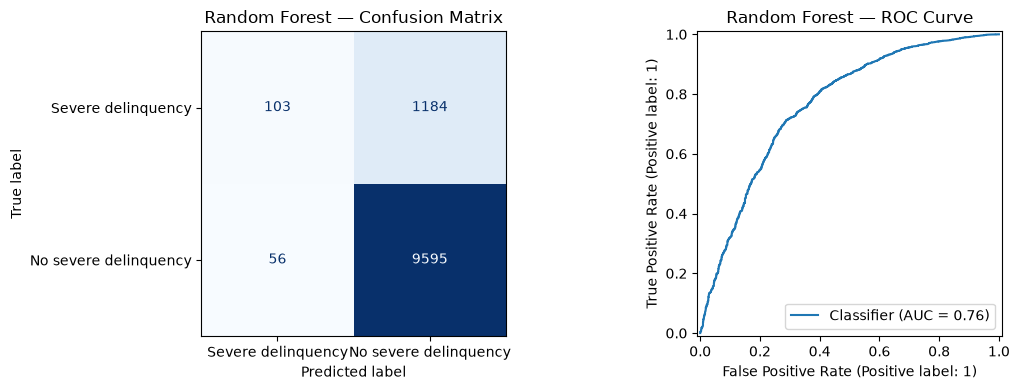

In [8]:
best_experiment_name = results_df.iloc[0]["Experiment"]
best_pipeline = searches[best_experiment_name].best_estimator_

best_model_name = results_df.iloc[0]["Model"]
print("Best experiment by test ROC-AUC:", best_experiment_name)
y_pred_best = best_pipeline.predict(X_test)
y_proba_best = best_pipeline.predict_proba(X_test)[:, 1]

print("\nClassification report:")
print(classification_report(
    y_test, y_pred_best,
    target_names=["0 = severe delinquency observed",
                  "1 = no severe delinquency observed"],
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_best,
    display_labels=["Severe delinquency", "No severe delinquency"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title(f"{best_model_name} — Confusion Matrix")

RocCurveDisplay.from_predictions(y_test, y_proba_best, ax=axes[1])
axes[1].set_title(f"{best_model_name} — ROC Curve")

plt.tight_layout()
plt.show()

## 6. Compare ROC curves across models

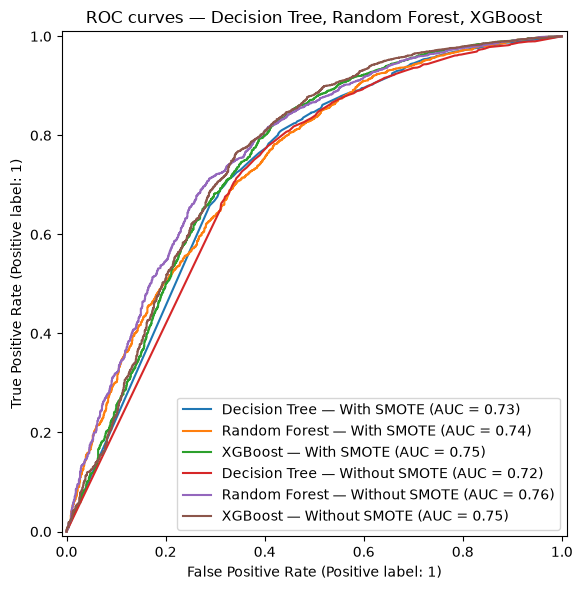

In [9]:
plt.figure(figsize=(8, 6))
for model_name, search in searches.items():
    model = search.best_estimator_
    probabilities = model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(
        y_test, probabilities, name=model_name, ax=plt.gca()
    )

plt.title("ROC curves — Decision Tree, Random Forest, XGBoost")
plt.tight_layout()
plt.show()

## 7. Feature importance and SHAP for XGBoost

SHAP is applied to the best XGBoost model. The explanation uses a sample of the test set to limit computation time.

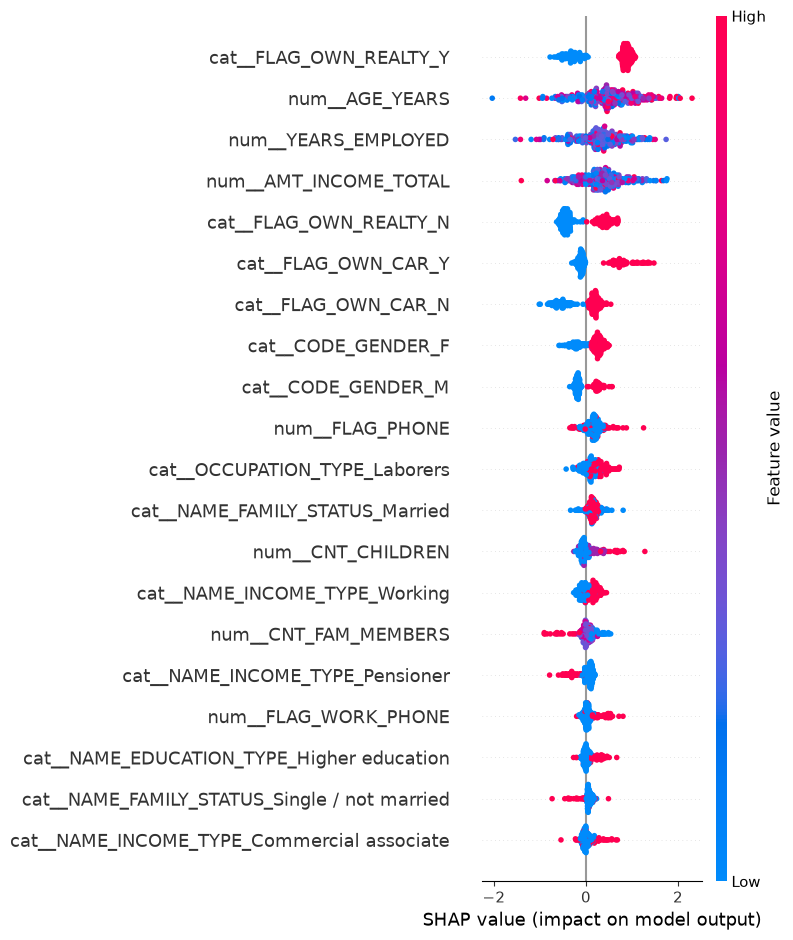

In [10]:
xgb_experiment_name = "XGBoost — With SMOTE"
xgb_pipeline = searches[xgb_experiment_name].best_estimator_
xgb_model = xgb_pipeline.named_steps["model"]
fitted_preprocessor = xgb_pipeline.named_steps["preprocess"]

# Transform a sample of the held-out test set.
X_shap_raw = X_test.sample(n=min(300, len(X_test)), random_state=RANDOM_STATE)
X_shap_transformed = fitted_preprocessor.transform(X_shap_raw)

# SHAP's plotting functions are easiest to use with a dense sample.
if hasattr(X_shap_transformed, "toarray"):
    X_shap_dense = X_shap_transformed.toarray()
else:
    X_shap_dense = np.asarray(X_shap_transformed)

feature_names = fitted_preprocessor.get_feature_names_out()

# TreeExplainer for the fitted XGBoost classifier.
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_shap_dense)

plt.figure()
shap.summary_plot(
    shap_values,
    features=X_shap_dense,
    feature_names=feature_names,
    show=False
)
plt.tight_layout()
plt.show()

## 8. Save model comparison results

The CSV contains the model metrics and best parameter settings from this run.

In [11]:
# Save results to the Kaggle working directory or local ./results directory
output_dir = "/kaggle/working" if os.path.exists("/kaggle/working") else "./results"
os.makedirs(output_dir, exist_ok=True)
output_csv_path = os.path.join(output_dir, "model_comparison_results.csv")

results_export = results_df.copy()
results_export["Best parameters"] = results_export["Best parameters"].astype(str)
results_export.to_csv(output_csv_path, index=False)

print(f"Saved: {output_csv_path}")
display(results_export[[
    "Experiment", "Model", "SMOTE", "Best CV ROC-AUC", "Test accuracy",
    "Test precision (class 1)", "Test recall (class 1)",
    "Test F1 (class 1)", "Test macro-F1", "Test ROC-AUC"
]])

Saved: ./results\model_comparison_results.csv


,Experiment,Model,SMOTE,Best CV ROC-AUC,Test accuracy,Test precision (class 1),Test recall (class 1),Test F1 (class 1),Test macro-F1,Test ROC-AUC
0,Random Forest — Without SMOTE,Random Forest,False,0.728202,0.886634,0.890157,0.994197,0.939305,0.540883,0.764163
1,XGBoost — Without SMOTE,XGBoost,False,0.709733,0.887091,0.905786,0.973267,0.938315,0.636273,0.752862
2,XGBoost — With SMOTE,XGBoost,True,0.709748,0.869172,0.916245,0.937416,0.926709,0.659016,0.746099
3,Random Forest — With SMOTE,Random Forest,True,0.718010,0.878223,0.903796,0.964667,0.933240,0.620466,0.739417
4,Decision Tree — With SMOTE,Decision Tree,True,0.685075,0.843024,0.916264,0.904777,0.910484,0.636689,0.729788
5,Decision Tree — Without SMOTE,Decision Tree,False,0.685903,0.865332,0.906380,0.944980,0.925278,0.622140,0.716985


## Notes for interpretation

- The thesis reports near-perfect scores (approximately 0.98–0.99 accuracy/F1), but these values are not guaranteed to reproduce unless the exact target, row-level dataset, feature processing, split, and resampling sequence match.
- This notebook uses the same thesis-reported model hyperparameters and a 70/30 split. It reports ROC-AUC as the GridSearchCV scoring metric and displays accuracy, precision, recall, F1, ROC-AUC, confusion matrix, feature importance, and SHAP.
- `credit_record.csv` records monthly payment status, not a true application approval decision. The target used here is explicitly a payment-history proxy.
- SMOTE is applied only within training folds to avoid test-set contamination. If the original implementation applied SMOTE before splitting, that methodological difference can affect the reported metrics.
- Compare the `With SMOTE` and `Without SMOTE` runs separately. Do not present the proxy classification as genuine bank approval prediction.
